# LineStacker examples

All LineStacker examples in one notebook, run on the example data shipped with
LineStacker (`Example/oneD` and `Example/cube`):

1. **One-dimensional stacking**: a basic stack of 100 spectra, then a median
   stack with bootstrapping and subsampling.
2. **Cube stacking**: the basic stack, the same stack from a catalogue and
   from Python arrays, then the extended example (line fits, spectral
   rebinning, bootstrapping).
3. **Continuum stacking** with the same function, and random-position stacks.

Run it from the `Example` folder. The example cubes are CASA images, so the
cube sections need CASA's Python packages (`pip install casatools`);
FITS cubes would need no CASA. Everything the notebook writes goes to
`notebook_outputs/`.

## Setup

In [1]:
import os
import sys
import glob

import numpy as np
import matplotlib.pyplot as plt

# Use the LineStacker of this repository (two folders up) if it is there,
# rather than another installed version.
REPO = os.path.abspath(os.path.join(os.getcwd(), '..', '..'))
if os.path.isfile(os.path.join(REPO, 'LineStacker', '__init__.py')):
    sys.path.insert(0, REPO)

import LineStacker
import LineStacker.OneD_Stacker
import LineStacker.image
import LineStacker.analysisTools
import LineStacker.tools.fit as fitTools

print('LineStacker', LineStacker.__version__, 'from', os.path.dirname(LineStacker.__file__))

EXAMPLE = os.getcwd()                         # this notebook's folder
OUT = os.path.join(EXAMPLE, 'notebook_outputs')
os.makedirs(OUT, exist_ok=True)

N_JOBS = -1                                   # Monte-Carlo tools: use all CPU cores
FEM = 1897420620253.1646                      # [CII] 158 um rest frequency (Hz)
plt.rcParams['figure.dpi'] = 80

LineStacker 2.0.0 from LineStacker


## 1. One-dimensional stacking

### 1.1 Basic stack

100 spectra (`oneD/data/spectra_<i>`), each with its line centre given as a
velocity (`central_velocity_<i>`). Every spectrum becomes a
`LineStacker.OneD_Stacker.Spectrum`; `Stack` aligns them on their line centre.
`Stack` returns the stacked spectrum and the number of spectra contributing to
each channel.

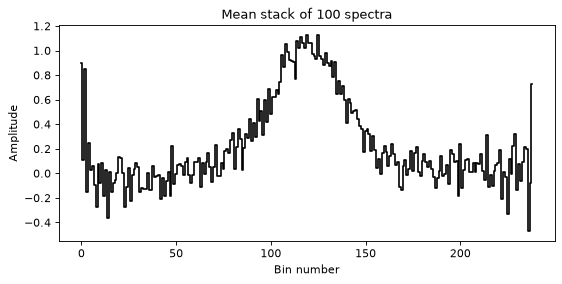

In [2]:
data = os.path.join(EXAMPLE, 'oneD', 'data')
spectra = [LineStacker.OneD_Stacker.Spectrum(spectrum=np.loadtxt(os.path.join(data, 'spectra_%d' % i)),
                                             centralVelocity=np.loadtxt(os.path.join(data, 'central_velocity_%d' % i)))
           for i in range(100)]
stacked, n_per_channel = LineStacker.OneD_Stacker.Stack(spectra)

fig, ax = plt.subplots(figsize=(8, 3.5))
ax.step(range(len(stacked)), stacked, where='mid', color='k')
ax.set_xlabel('Bin number')
ax.set_ylabel('Amplitude')
ax.set_title('Mean stack of %d spectra' % len(spectra))
plt.show()

### 1.2 Median stack, bootstrapping and subsampling

50 spectra (`oneD/dataExtended`): 40 have a line of amplitude 1 and 10
(numbers 40 to 49) a line of amplitude 10. Naming the spectra makes the
subsampling results readable.

In [3]:
data = os.path.join(EXAMPLE, 'oneD', 'dataExtended')
names = ['spectrum_%d' % i for i in range(50)]
spectra = [LineStacker.OneD_Stacker.Spectrum(spectrum=np.loadtxt(os.path.join(data, 'spectra_%d' % i)),
                                             centralVelocity=np.loadtxt(os.path.join(data, 'central_velocity_%d' % i)),
                                             name=names[i])
           for i in range(50)]
stacked, _ = LineStacker.OneD_Stacker.Stack(spectra, method='median')
stackAmp = np.max(stacked)
print('amplitude of the median stack: %.3f' % stackAmp)

amplitude of the median stack: 1.774


**Bootstrapping**: stack spectra drawn with replacement many times, here
saving the amplitude of each stack. The original example uses
`nRandom=100000`; 10 000 is enough to see the distribution and runs in seconds.
`seed` makes the draws reproducible, and the result does not depend on `n_jobs`.

LineStacker: bootstrapping 50 spectra, 10000 iterations
|          | LOADING  100%



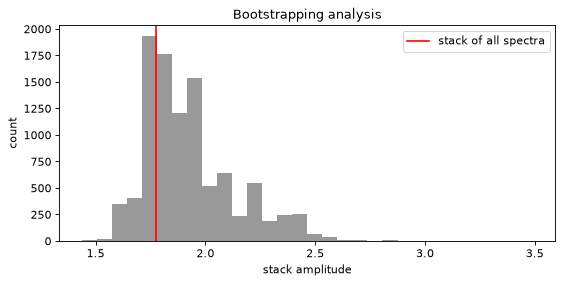

In [4]:
bootstrapped = LineStacker.analysisTools.bootstraping_OneD(spectra, save='amp', nRandom=10000,
                                                           method='median', seed=1, n_jobs=N_JOBS)

fig, ax = plt.subplots(figsize=(8, 3.5))
ax.hist(bootstrapped, bins=30, color='0.6')
ax.axvline(stackAmp, color='red', label='stack of all spectra')
ax.set_xlabel('stack amplitude')
ax.set_ylabel('count')
ax.set_title('Bootstrapping analysis')
ax.legend()
plt.show()

The distribution has several peaks: some draws contain more of the bright
spectra than others. **Subsampling** finds which spectra are responsible: random
subsets are stacked and graded (by default `maximizeSNR`, the signal to noise of
a Gaussian fit), and every spectrum collects the grades of the subsets it was in.
The bright spectra come out on top already with 10 000 iterations.

LineStacker: subsampling 50 spectra, 10000 iterations
|          | LOADING  100%



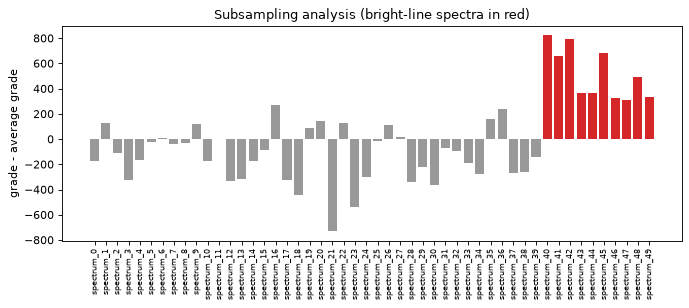

In [5]:
grades = LineStacker.analysisTools.subsample_OneD(spectra, nRandom=10000, method='median',
                                                  seed=1, n_jobs=N_JOBS)
meanGrade = np.mean(list(grades.values()))

fig, ax = plt.subplots(figsize=(10, 3.5))
ax.bar(range(len(names)), [grades[n] - meanGrade for n in names],
       color=['0.6'] * 40 + ['tab:red'] * 10)
ax.set_xticks(range(len(names)))
ax.set_xticklabels(names, rotation='vertical', fontsize=7)
ax.set_ylabel('grade - average grade')
ax.set_title('Subsampling analysis (bright-line spectra in red)')
plt.show()

## 2. Cube stacking

### 2.1 Basic stack from coordinate files

The classic input: one coordinate file per cube (`<cube>_coord.txt`, one line
`RA, Dec, z` per source), here 30 cubes of the [CII] line. Instead of the file
dialog (`LineStacker.readCoordsNamesGUI()`) the files are listed with `glob`.
The redshift gives the line centre, so the rest frequency `fEm` is needed.
LineStacker prints where it wrote the stacked cube (`LineStacker.verbose`).

In [6]:
coordNames = sorted(glob.glob(os.path.join(EXAMPLE, 'cube', 'data', '*_coord.txt')))
coords = LineStacker.readCoords(coordNames)
imagenames = [c.removesuffix('_coord.txt') + '.image' for c in coordNames]

stacked = LineStacker.image.stack(coords, imagenames=imagenames, fEm=FEM, stampsize=16, N_chans=16,
                                  outfile=os.path.join(OUT, 'stackResult.fits'))
centralValue, centralSpectrum, stackCube, missing = stacked

LineStacker: read 30 positions from 30 coordinate files
LineStacker: mean line stack of 30 sources (16x16 pixels, 16 channels) written to LineStacker/Example/notebook_outputs/stackResult.fits


`stack` returns the central pixel at the central channel, the spectrum of the
central pixel, the stacked cube (axes x, y, Stokes, channel) and how many
sources miss each channel (sources whose cube does not cover it).

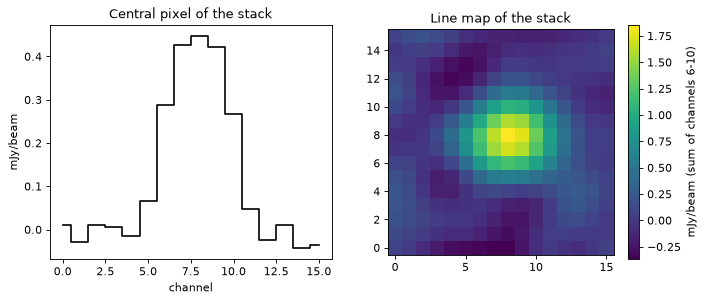

In [7]:
line = slice(6, 11)                                    # channels around the line
fig, axes = plt.subplots(1, 2, figsize=(10, 3.8))
axes[0].step(range(16), centralSpectrum * 1e3, where='mid', color='k')
axes[0].set_xlabel('channel')
axes[0].set_ylabel('mJy/beam')
axes[0].set_title('Central pixel of the stack')
im = axes[1].imshow(stackCube[:, :, 0, line].sum(axis=2).T * 1e3, origin='lower')
fig.colorbar(im, ax=axes[1], label='mJy/beam (sum of channels 6-10)')
axes[1].set_title('Line map of the stack')
plt.show()

### 2.2 The same stack from a catalogue

One table for the whole sample, one row per source, with the cube of each
source named in an `image` column. `readCatalog` reads CSV, ECSV, FITS tables,
VOTable (anything `astropy.table` reads), an astropy `Table` or a pandas
`DataFrame`. Positions can be in degrees or sexagesimal (RA in hours,
CASA's `-027.40.59.866` included). Relative cube names are looked up next to
the catalogue first.

Here the catalogue is written from the coordinate files above, with cube
names relative to the catalogue; normally it comes from your own catalogue
(TOPCAT, a database query...).

In [8]:
catalog = os.path.join(OUT, 'basic_catalog.csv')
with open(catalog, 'w') as fh:
    fh.write('ra,dec,z,image\n')
    for c in coords:
        cube = c.image.removesuffix('.fits') + '.image'
        fh.write('%.8f,%.8f,%.10f,%s\n' % (c.ra.deg, c.dec.deg, c.z, os.path.relpath(cube, OUT)))
print(''.join(open(catalog).readlines()[:4]) + '...')

ra,dec,z,image
52.76729167,-27.68329611,7.2657160664,../cube/data/basicExampleCube_10071.image
52.81320833,-27.57057417,7.2219053565,../cube/data/basicExampleCube_14115.image
52.64495833,-27.75960167,7.2261167585,../cube/data/basicExampleCube_16612.image
...


In [9]:
coordsCat = LineStacker.readCatalog(catalog)
stackedCat = LineStacker.image.stack(coordsCat, fEm=FEM, stampsize=16, N_chans=16, outfile=None)  # no imagenames needed
print('same stack as from the coordinate files:', np.allclose(stackedCat[2], stackCube, rtol=1e-6, atol=1e-9))

LineStacker: read 30 positions in 30 cubes from basic_catalog.csv
LineStacker: mean line stack of 30 sources (16x16 pixels, 16 channels) done (outfile=None: not written to disk)
same stack as from the coordinate files: True


Columns can have other names: `readCatalog(cat, ra='RAJ2000', dec='DEJ2000', z='zspec', image='cube')`
(common names such as `RAJ2000`, `redshift`, `cube` are found automatically). An
optional `weight` column gives weights for mean stacks. Without a `z` column the
positions are for continuum stacking. Without an `image` column, all sources
must lie in the single cube given as `imagenames`; LineStacker never guesses
which cube a source belongs to.

### 2.3 The same stack from Python arrays

`makeCoords` builds the coordinates from lists, numpy arrays, astropy
quantities or a `SkyCoord`; `image` can be one cube for all sources or one per
source.

In [10]:
ra = np.array([c.ra.deg for c in coords])        # e.g. columns of your own catalogue
dec = np.array([c.dec.deg for c in coords])
z = np.array([c.z for c in coords])

coordsArr = LineStacker.makeCoords(ra, dec, z=z, image=imagenames)
stackedArr = LineStacker.image.stack(coordsArr, fEm=FEM, stampsize=16, N_chans=16, outfile=None)
print('same stack:', np.allclose(stackedArr[2], stackCube, rtol=1e-6, atol=1e-9))

LineStacker: made 30 coordinates
LineStacker: mean line stack of 30 sources (16x16 pixels, 16 channels) done (outfile=None: not written to disk)
same stack: True


### 2.4 Extended example: line profiles, rebinning and bootstrapping

50 cubes (`cube/dataExtended`) whose lines have different widths. First the
stack, and the spectrum of each cube (central 5x5 pixels, read with
`LineStacker.image.readCube`, which reads FITS files and CASA images alike).

LineStacker: read 50 positions from 50 coordinate files
LineStacker: mean line stack of 50 sources (16x16 pixels, 16 channels) written to LineStacker/Example/notebook_outputs/stackResult_extended.fits


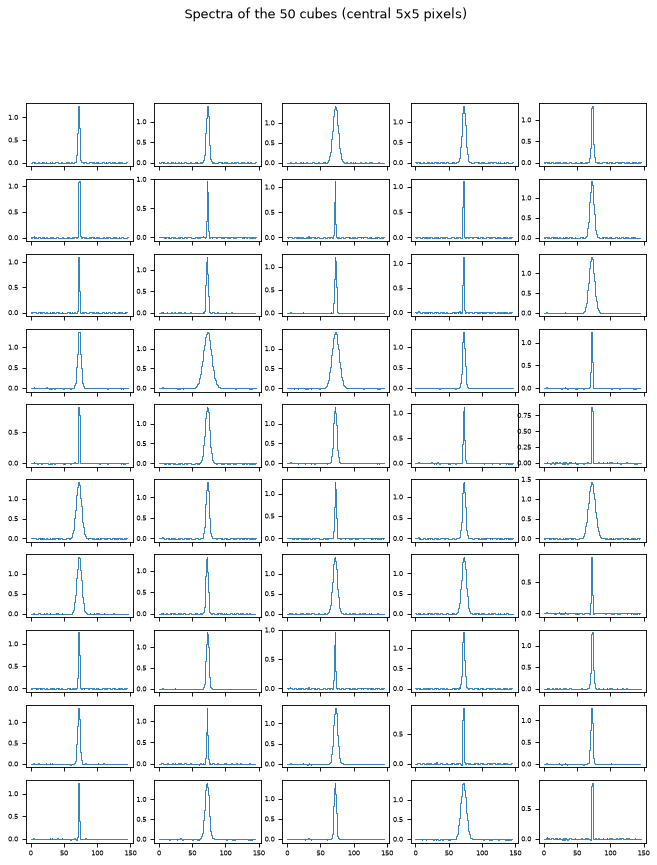

In [11]:
coordNames = sorted(glob.glob(os.path.join(EXAMPLE, 'cube', 'dataExtended', '*_coord.txt')))
coords = LineStacker.readCoords(coordNames)
imagenames = [c.removesuffix('_coord.txt') + '.image' for c in coordNames]
stacked = LineStacker.image.stack(coords, imagenames=imagenames, fEm=FEM, N_chans=16, stampsize=16,
                                  outfile=os.path.join(OUT, 'stackResult_extended.fits'))

fig, axes = plt.subplots(10, 5, figsize=(10, 12), sharex=True)
for ax, name in zip(axes.ravel(), imagenames):
    pix = LineStacker.image.readCube(name)
    c = pix.shape[0] // 2
    ax.step(range(pix.shape[3]), pix[c - 2:c + 3, c - 2:c + 3, :, :].sum(axis=(0, 1, 2)), where='mid', lw=0.8)
    ax.tick_params(labelsize=6)
fig.suptitle('Spectra of the 50 cubes (central 5x5 pixels)')
plt.show()

The spectrum of the stack, summed over the stamp, fitted with one and with two
Gaussians. The narrow core plus broad wings come from stacking lines of
different widths.

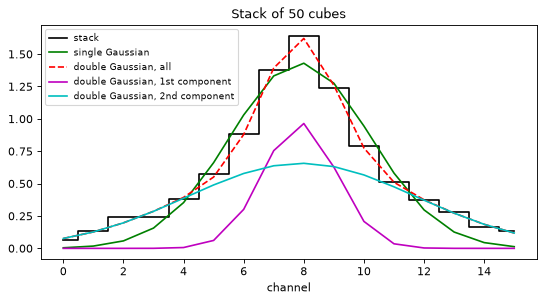

In [12]:
import warnings
from scipy.optimize import OptimizeWarning

def plot_fits(spectrum, x, title, xlabel):
    with warnings.catch_warnings():
        # a double Gaussian is degenerate for a single-component line
        warnings.simplefilter('ignore', OptimizeWarning)
        single = fitTools.GaussFit(fctToFit=spectrum)
        double = fitTools.DoubleGaussFit(fctToFit=spectrum, returnAllComp=True)
    fig, ax = plt.subplots(figsize=(8, 3.8))
    ax.step(x, spectrum, 'k', where='mid', label='stack')
    ax.plot(x, single, 'g', label='single Gaussian')
    ax.plot(x, double[0], 'r--', label='double Gaussian, all')
    ax.plot(x, double[1], 'm', label='double Gaussian, 1st component')
    ax.plot(x, double[2], 'c', label='double Gaussian, 2nd component')
    ax.set_xlabel(xlabel)
    ax.set_title(title)
    ax.legend(fontsize=8)
    plt.show()

integrated = stacked[2].sum(axis=(0, 1, 2))
plot_fits(integrated, range(len(integrated)), 'Stack of 50 cubes', 'channel')

**Spectral rebinning**: each cube is resampled so that all lines get the width
of the narrowest one (the widths come from Gaussian fits of each cube's
spectrum). The rebinned cubes are written to `notebook_outputs/rebinned`, then
stacked; the stacked line is now a single Gaussian. The velocity axis comes
from the header of the stacked cube.

LineStacker: rebinning 50 cubes to the narrowest line width
|          | LOADING  100%

LineStacker: 50 rebinned cubes written: in LineStacker/Example/notebook_outputs/rebinned (extendedExampleCube_10619_SpectralRebinned.image ... extendedExampleCube_97379_SpectralRebinned.image)
LineStacker: mean line stack of 50 sources (16x16 pixels, 16 channels) written to LineStacker/Example/notebook_outputs/stackResult_rebinned.fits


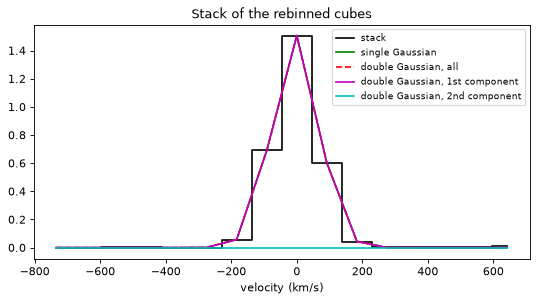

In [13]:
rebinned = LineStacker.analysisTools.rebin_CubesSpectra(coords, imagenames, outdir=os.path.join(OUT, 'rebinned'))
outfile = os.path.join(OUT, 'stackResult_rebinned.fits')
rebinnedStack = LineStacker.image.stack(coords, imagenames=rebinned, fEm=FEM, N_chans=16, stampsize=16,
                                        outfile=outfile)

from astropy.io import fits
h = fits.getheader(outfile)
channels = np.arange(h['NAXIS3'])
freq = h['CRVAL3'] + (channels + 1 - h['CRPIX3']) * h['CDELT3']
velocity = 299792.458 * (h['RESTFRQ'] - freq) / h['RESTFRQ']      # radio convention, km/s
plot_fits(rebinnedStack[2].sum(axis=(0, 1, 2)), velocity, 'Stack of the rebinned cubes', 'velocity (km/s)')

**Bootstrapping the cube stack**, saving the amplitude and width of a Gaussian
fit of each bootstrapped stack (fits are spread over all cores).

LineStacker: bootstrapping 50 sources, 2000 iterations
|          | LOADING  100%



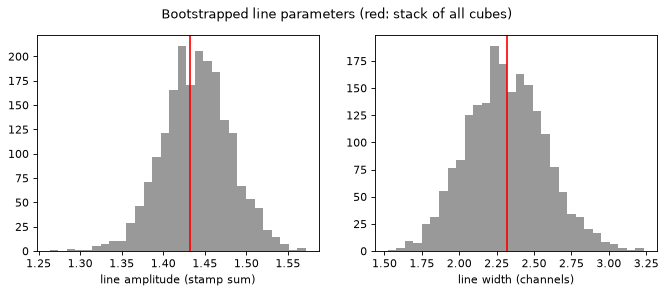

amplitude 1.4317 +- 0.0407, width 2.32 +- 0.26 channels


In [14]:
boot = LineStacker.analysisTools.bootStraping_Cube(coords, imagenames=imagenames, fEm=FEM, N_chans=16,
                                                   stampsize=16, nRandom=2000, save='ampAndWidth',
                                                   seed=1, n_jobs=N_JOBS)
amp, width = np.array(boot[1:], dtype=float).T

fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
axes[0].hist(amp, bins=30, color='0.6')
axes[0].axvline(boot[0][0], color='red')
axes[0].set_xlabel('line amplitude (stamp sum)')
axes[1].hist(np.abs(width), bins=30, color='0.6')
axes[1].axvline(abs(boot[0][1]), color='red')
axes[1].set_xlabel('line width (channels)')
fig.suptitle('Bootstrapped line parameters (red: stack of all cubes)')
plt.show()
print('amplitude %.4f +- %.4f, width %.2f +- %.2f channels' % (boot[0][0], np.nanstd(amp), abs(boot[0][1]), np.nanstd(np.abs(width))))

## 3. Continuum stacking

The same `stack` function, with `continuum=True`. The example cubes have a
spectral axis, so LineStacker warns and stacks the images summed over channels
(`collapse='sum'`, the default; `'mean'` and `'median'` are possible), made in
memory. Images without a spectral axis are stacked as continuum automatically,
without warning.

LineStacker: read 30 positions from 30 coordinate files


<cell>:5: UserWarning: continuum stacking (continuum=True): collapsing 30 cube(s) with a spectral axis (sum over channels) in memory
  continuum = LineStacker.image.stack(coords, imagenames=imagenames, stampsize=16, continuum=True,


LineStacker: mean continuum stack of 30 sources (16x16 pixels) written to LineStacker/Example/notebook_outputs/continuumStack.fits


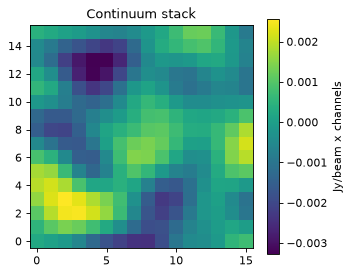

In [15]:
coordNames = sorted(glob.glob(os.path.join(EXAMPLE, 'cube', 'data', '*_coord.txt')))
coords = LineStacker.readCoords(coordNames)
imagenames = [c.removesuffix('_coord.txt') + '.image' for c in coordNames]

continuum = LineStacker.image.stack(coords, imagenames=imagenames, stampsize=16, continuum=True,
                                    outfile=os.path.join(OUT, 'continuumStack.fits'))

fig, ax = plt.subplots(figsize=(4.5, 3.8))
im = ax.imshow(continuum[2][:, :, 0, 0].T, origin='lower')
fig.colorbar(im, ax=ax, label='Jy/beam x channels')
ax.set_title('Continuum stack')
plt.show()

**Stacks at random positions** tell how significant the stacked value is: each
source is moved to a random position (here 4 to 9 microradians, about 0.8" to
1.9", away; the example cubes are only 6" wide) and the stack is repeated.

LineStacker: stacking 2000 sets of random positions around 30 sources
|          | LOADING 25% 

<cell>:1: UserWarning: continuum stacking (continuum=True): collapsing 30 cube(s) with a spectral axis (sum over channels) in memory
  random = LineStacker.analysisTools.stack_estimator(coords, imagenames=imagenames, continuum=True, nRandom=2000,


|          | LOADING  100%



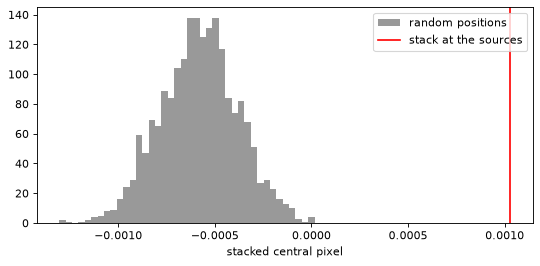

stack 0.00103, random positions -0.000582 +- 0.000201


In [16]:
random = LineStacker.analysisTools.stack_estimator(coords, imagenames=imagenames, continuum=True, nRandom=2000,
                                                   lowerLimit=4e-6, upperLimit=9e-6, seed=1, n_jobs=N_JOBS)
std, mean, dist = random

fig, ax = plt.subplots(figsize=(8, 3.5))
ax.hist(np.ravel(dist), bins=40, color='0.6', label='random positions')
ax.axvline(continuum[0], color='red', label='stack at the sources')
ax.set_xlabel('stacked central pixel')
ax.legend()
plt.show()
print('stack %.3g, random positions %.3g +- %.3g' % (continuum[0], mean, std))

The random positions give negative values on average: they fall in the
negative sidelobes of the dirty beam around each source, as the example cubes
are small. On real data, use limits of several beams (the default,
5 to 10 beams).

## 4. Good to know

- `LineStacker.verbose = False` silences LineStacker's messages and progress
  bars; any function also takes `verbose=True/False`.
- `outfile` names ending in `.fits` are written as FITS, other names (e.g.
  `stackResult.image`) as CASA images.
- The Monte-Carlo tools take `n_jobs` (cores, -1 for all) and `seed`; results
  do not depend on `n_jobs`.